In [7]:
# Names

# Amanda Le (al58528)
# Hannah Fan (hlf583)
# Rianna Skaria (rrs3385)
# Prithikaa Sadagopan (ps35493)

# Predicting Sleep Debt Severity from Evening Technology Habits

## Introduction

Sleep debt occurs when an individual does not obtain sufficient
sleep relative to their sleep needs. Understanding the relationship
between evening technology habits and sleep debt may help identify
patterns associated with insufficient sleep.

In this project, we investigate whether sleep debt severity can
be predicted using demographic characteristics, evening phone
habits, and other lifestyle variables.

## Dataset

Our dataset contains 8,500 observations and 17 features describing
individuals' lifestyle habits, technology use, and sleep-related
measurements.

link: https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits

In [4]:
# standard headers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# load data set
sleep = pd.read_csv('bedtime_screentime_sleep_debt.csv')
print(sleep.shape)
display(sleep.head())

(8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [10]:
# check data types and non-null counts
sleep.info()

# count missing values in each column
missingCount = sleep.isna().sum()
print(missingCount)

# print the total number of missing values
print("Total missing values:", sleep.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   str    
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   str    
 3   occupation_type           8500 non-null   str    
 4   chronotype                8500 non-null   str    
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   str    
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_sleep_pct      

### Data Exploration

In [11]:
# check for duplicate rows and duplicate user IDs
print("Duplicate rows:", sleep.duplicated().sum())
print("Unique user IDs:", sleep["user_id"].nunique())

# examine the target distribution
display(sleep["sleep_debt_category"].value_counts())
display(sleep["sleep_debt_category"].value_counts(normalize=True))

Duplicate rows: 0
Unique user IDs: 8500


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

sleep_debt_category
Moderate Debt        0.524941
Mild Deficit         0.235765
Optimal Recovery     0.163176
Severe Sleep Debt    0.076118
Name: proportion, dtype: float64

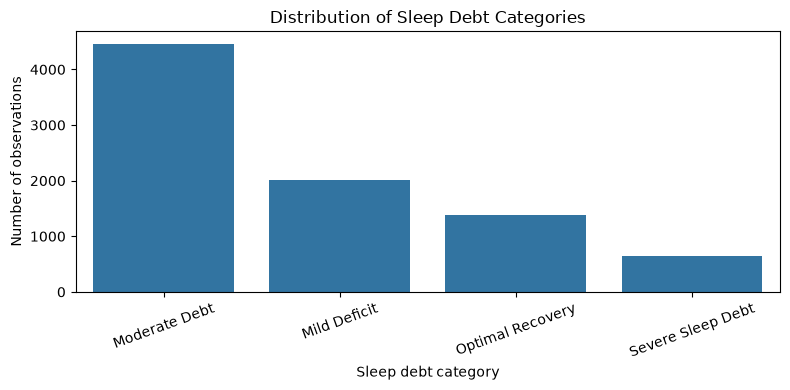

In [12]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=sleep,
    x="sleep_debt_category",
    order=sleep["sleep_debt_category"].value_counts().index
)
plt.title("Distribution of Sleep Debt Categories")
plt.xlabel("Sleep debt category")
plt.ylabel("Number of observations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# The chart above shows class imbalace, with moderate debt being the majority of the data (about 52.5%) and severe sleep debt being about 7.6%

In [ ]:
# compare numeric variables across sleep-debt categories
numeric_to_compare = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "morning_alarm_snoozes",
    "sleep_latency_min",
    "total_sleep_hours",
    "next_day_fatigue_score"
]

display(
    sleep.groupby("sleep_debt_category")[numeric_to_compare]
    .agg(["mean", "median"])
    .round(2)
)

age        bedtime_phone_minutes         \
                      mean median                  mean median   
sleep_debt_category                                              
Mild Deficit         34.37   32.0                 45.45   43.0   
Moderate Debt        34.38   32.0                 64.12   60.0   
Optimal Recovery     34.70   32.0                 33.51   30.0   
Severe Sleep Debt    33.45   30.0                123.60  125.0   

                    screen_brightness_pct        caffeine_post_5pm_mg         \
                                     mean median                 mean median   
sleep_debt_category                                                            
Mild Deficit                        55.37   56.0                33.03    0.0   
Moderate Debt                       54.52   55.0                31.56    0.0   
Optimal Recovery                    54.24   55.0                30.24    0.0   
Severe Sleep Debt                   60.80   60.0                51.66   25.0   

                    physical_activity_min        morning_alarm_snoozes         \
                                     mean median                  mean median   
sleep_debt_category                                                             
Mild Deficit                        35.27   35.0                  1.81    2.0   
Moderate Debt                       35.97   36.0                  3.35    3.0   
Optimal Recovery                    36.11   35.0                  0.81    1.0   
Severe Sleep Debt                   34.30   32.0                  5.88    6.0   

                    sleep_latency_min        total_sleep_hours         \
                                 mean median              mean median   
sleep_debt_category                                                     
Mild Deficit                    34.69   33.4              7.23   7.21   
Moderate Debt                   42.37   40.7              5.55   5.66   
Optimal Recovery                28.92   28.0              8.35   8.23   
Severe Sleep Debt               72.70   72.9              3.76   3.59   

                    next_day_fatigue_score         
                                      mean median  
sleep_debt_category                                
Mild Deficit                          1.83    1.4  
Moderate Debt                         4.68    4.6  
Optimal Recovery                      1.08    1.0  
Severe Sleep Debt                     9.58    9.9

In [ ]:
# Severe Sleep Debt showed the highest in bedtime phone usage, sleep latency, caffeine intake, alarm snoozes, and next-day fatigue, along with the lowest total sleep duration. Optimal Recovery showed the opposite patterns for most of these variables. Age was relatively consistent across categories, suggesting it may be less useful for distinguishing sleep-debt severity.